## **Data Loading and Understanding**

In [1]:
import os
print(os.getcwd())

C:\credit-risk-ml-pipeline


In [2]:
import sys
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
print(sys.executable)

C:\credit-risk-ml-pipeline\venv\Scripts\python.exe


In [3]:
import pandas, sklearn, xgboost, mlflow
print("All good")

All good


In [4]:
pip install openpyxl

Note: you may need to restart the kernel to use updated packages.


In [5]:
import pandas as pd
import os

print("Working directory:", os.getcwd())

df = pd.read_excel('Data/german_credit_data.xlsx')
print(df.shape)
df.head()

Working directory: C:\credit-risk-ml-pipeline
(1000, 10)


,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,56,male,1,own,little,moderate,6745,22,car,good
1,69,female,2,free,moderate,moderate,10437,70,car,good
2,46,male,3,own,quite rich,little,9763,8,car,good
3,32,female,1,own,moderate,little,18964,70,radio/TV,bad
4,60,male,2,own,moderate,little,17650,14,domestic appliances,good


In [6]:
df.info

<bound method DataFrame.info of      Age     Sex  Job Housing Saving accounts Checking account  Credit amount  \
0     56    male    1     own          little         moderate           6745   
1     69  female    2    free        moderate         moderate          10437   
2     46    male    3     own      quite rich           little           9763   
3     32  female    1     own        moderate           little          18964   
4     60    male    2     own        moderate           little          17650   
..   ...     ...  ...     ...             ...              ...            ...   
995   37    male    1     own          little           little          11121   
996   41    male    3     own      quite rich           little           7860   
997   22    male    2    free          little           little          11327   
998   51    male    0    rent        moderate           little          16041   
999   23  female    0    rent          little           little           2794

In [7]:
rename_map = {
    'Age': 'age', 'Sex': 'sex', 'Job': 'job', 'Housing': 'housing',
    'Saving accounts': 'savings_account', 'Checking account': 'checking_account',
    'Credit amount': 'credit_amount', 'Duration': 'duration_months',
    'Purpose': 'purpose', 'Risk': 'credit_risk'
}
df = df.rename(columns=rename_map)
df.head()

,age,sex,job,housing,savings_account,checking_account,credit_amount,duration_months,purpose,credit_risk
0,56,male,1,own,little,moderate,6745,22,car,good
1,69,female,2,free,moderate,moderate,10437,70,car,good
2,46,male,3,own,quite rich,little,9763,8,car,good
3,32,female,1,own,moderate,little,18964,70,radio/TV,bad
4,60,male,2,own,moderate,little,17650,14,domestic appliances,good


In [8]:
df['credit_risk'] = df['credit_risk'].map({'good': 0, 'bad': 1})
df['credit_risk'].value_counts(normalize=True) * 100

credit_risk
0    60.4
1    39.6
Name: proportion, dtype: float64

In [9]:
df[['age', 'credit_amount', 'duration_months']].describe()

,age,credit_amount,duration_months
count,1000.000000,1000.000000,1000.000000
mean,46.247000,9943.912000,36.810000
std,16.288072,5626.476201,19.334418
min,18.000000,298.000000,4.000000
25%,33.000000,5021.250000,21.000000
50%,46.000000,9814.000000,36.000000
75%,60.250000,14785.500000,53.000000
max,74.000000,19893.000000,71.000000


In [10]:
print("Duplicate rows:", df.duplicated().sum()," \n\n\n")
print("\nMissing values per column:\n", df.isnull().sum(),"\n\n\n")
print("\nClass balance:\n", df['credit_risk'].value_counts(normalize=True) * 100)

Duplicate rows: 0  




Missing values per column:
 age                  0
sex                  0
job                  0
housing              0
savings_account     85
checking_account    95
credit_amount        0
duration_months      0
purpose              0
credit_risk          0
dtype: int64 




Class balance:
 credit_risk
0    60.4
1    39.6
Name: proportion, dtype: float64


## **EDA**

**Section 2**, Exploratory Data Analysis:** Tested a hypothesis that missing values meant "no account exists" rather than random gaps. Found only 6 rows missing both columns at once, meaning the two patterns are mostly independent. Found strong evidence supporting the hypothesis for savings_account specifically — people missing that value had a 58.7% bad-credit rate versus 37% for others — but much weaker evidence for checking_account, where the gap was minimal. Looked at distributions of age, credit_amount, and duration_months — all roughly evenly spread, no major skew. Compared these numeric columns against credit risk using boxplots, finding credit_amount and duration_months clearly differ between good and bad credit groups, while age barely differs. Checked categorical columns against credit risk, finding savings_account and checking_account balance level to be the strongest predictors, purpose showing a moderate spread, and sex and housing showing weak, flat differences.

**60.4% good / 39.6% bad — moderately imbalanced. Not extreme, but worth flagging: a lazy model that just predicts "good" for every single applicant would score 60.4% accuracy while being completely useless — it would approve every bad-credit applicant too. This is exactly why accuracy alone is a misleading metric here, and why we'll lean on precision/recall/F1 for the "bad" class specifically once we get to evaluation. Keep this number in your back pocket for the report.**

In [11]:
#Find rows where both account is missing.
both_missing = df[df['savings_account'].isnull() & df['checking_account'].isnull()]
print("Rows missing BOTH savings_account and checking_account:", len(both_missing))
print("both_missing")
# Create missing-flag columns (True/False)
df['savings_missing'] = df['savings_account'].isnull()
df['checking_missing'] = df['checking_account'].isnull()

# Does missingness relate to the target? Compare bad-credit rate for missing vs not-missing
print("\nBad-credit rate by savings_account missingness:")
print(df.groupby('savings_missing')['credit_risk'].mean())

print("\nBad-credit rate by checking_account missingness:")
print(df.groupby('checking_missing')['credit_risk'].mean())

Rows missing BOTH savings_account and checking_account: 6
both_missing

Bad-credit rate by savings_account missingness:
savings_missing
False    0.378142
True     0.588235
Name: credit_risk, dtype: float64

Bad-credit rate by checking_account missingness:
checking_missing
False    0.393370
True     0.421053
Name: credit_risk, dtype: float64


In [12]:
df[['age', 'credit_amount', 'duration_months']].describe()

,age,credit_amount,duration_months
count,1000.000000,1000.000000,1000.000000
mean,46.247000,9943.912000,36.810000
std,16.288072,5626.476201,19.334418
min,18.000000,298.000000,4.000000
25%,33.000000,5021.250000,21.000000
50%,46.000000,9814.000000,36.000000
75%,60.250000,14785.500000,53.000000
max,74.000000,19893.000000,71.000000


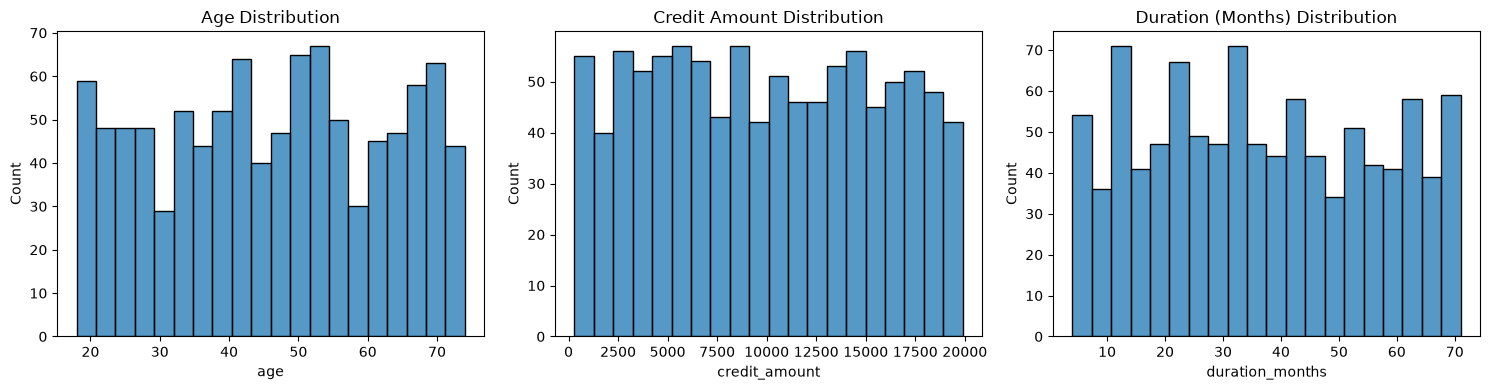

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(df['age'], bins=20, ax=axes[0])
axes[0].set_title('Age Distribution')

sns.histplot(df['credit_amount'], bins=20, ax=axes[1])
axes[1].set_title('Credit Amount Distribution')

sns.histplot(df['duration_months'], bins=20, ax=axes[2])
axes[2].set_title('Duration (Months) Distribution')

plt.tight_layout()
plt.show()

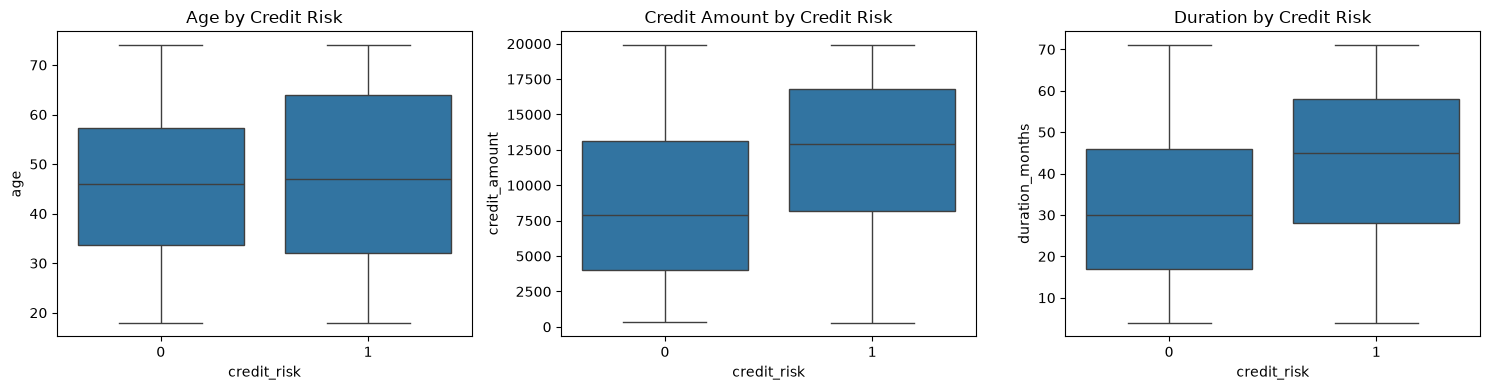

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.boxplot(x='credit_risk', y='age', data=df, ax=axes[0])
axes[0].set_title('Age by Credit Risk')

sns.boxplot(x='credit_risk', y='credit_amount', data=df, ax=axes[1])
axes[1].set_title('Credit Amount by Credit Risk')

sns.boxplot(x='credit_risk', y='duration_months', data=df, ax=axes[2])
axes[2].set_title('Duration by Credit Risk')

plt.tight_layout()
plt.show()

In [15]:
categorical_cols = ['sex', 'housing', 'savings_account', 'checking_account', 'purpose']

for col in categorical_cols:
    print(f"\nBad-credit rate by {col}:")
    print(df.groupby(col)['credit_risk'].mean().sort_values(ascending=False))


Bad-credit rate by sex:
sex
male      0.416826
female    0.373166
Name: credit_risk, dtype: float64

Bad-credit rate by housing:
housing
rent    0.401294
own     0.395586
free    0.382353
Name: credit_risk, dtype: float64

Bad-credit rate by savings_account:
savings_account
little        0.587379
rich          0.282051
moderate      0.184818
quite rich    0.180723
Name: credit_risk, dtype: float64

Bad-credit rate by checking_account:
checking_account
little      0.497030
moderate    0.271698
rich        0.244444
Name: credit_risk, dtype: float64

Bad-credit rate by purpose:
purpose
business               0.504505
domestic appliances    0.477612
vacation/others        0.395833
car                    0.391003
radio/TV               0.382653
education              0.366972
repairs                0.363636
furniture              0.330882
Name: credit_risk, dtype: float64


In [16]:
categorical_cols = ['sex', 'housing', 'savings_account', 'checking_account', 'purpose']

for col in categorical_cols:
    print(f"\nBad-credit rate by {col}:")
    print(df.groupby(col)['credit_risk'].mean().sort_values(ascending=False))


Bad-credit rate by sex:
sex
male      0.416826
female    0.373166
Name: credit_risk, dtype: float64

Bad-credit rate by housing:
housing
rent    0.401294
own     0.395586
free    0.382353
Name: credit_risk, dtype: float64

Bad-credit rate by savings_account:
savings_account
little        0.587379
rich          0.282051
moderate      0.184818
quite rich    0.180723
Name: credit_risk, dtype: float64

Bad-credit rate by checking_account:
checking_account
little      0.497030
moderate    0.271698
rich        0.244444
Name: credit_risk, dtype: float64

Bad-credit rate by purpose:
purpose
business               0.504505
domestic appliances    0.477612
vacation/others        0.395833
car                    0.391003
radio/TV               0.382653
education              0.366972
repairs                0.363636
furniture              0.330882
Name: credit_risk, dtype: float64


## **Preprosessing & Feature Engineering**

**Section 3**, Preprocessing and Feature Engineering:** Filled missing values in savings_account and checking_account with an explicit "none" category, rather than guessing the most common value, to preserve the real signal we found. Dropped the checking_missing flag column since it showed no useful signal, kept savings_missing since it did. Encoded savings_account and checking_account as ordinal ranked numbers, since their categories have a genuine order. One-hot encoded sex, housing, and purpose, since those categories have no natural order. Standardized age, credit_amount, and duration_months, since their raw ranges were wildly different from each other, to prevent the model from being biased toward features with naturally bigger numbers. Finally, split the data into a training set of 800 rows and a test set of 200 rows, using stratification to preserve the 60/40 class balance in both, setting up an honest way to evaluate the model later on data it's never seen.

In [17]:
df['savings_account'] = df['savings_account'].fillna('none')
df['checking_account'] = df['checking_account'].fillna('none')

print(df['savings_account'].value_counts())
print()
print(df['checking_account'].value_counts())

savings_account
little        412
moderate      303
rich          117
none           85
quite rich     83
Name: count, dtype: int64

checking_account
little      505
moderate    265
rich        135
none         95
Name: count, dtype: int64


In [18]:
print(df.groupby('savings_missing')['credit_risk'].mean())

savings_missing
False    0.378142
True     0.588235
Name: credit_risk, dtype: float64


In [19]:
both_missing = df[df['savings_account'].isnull() & df['checking_account'].isnull()]
print("Rows missing BOTH savings_account and checking_account:", len(both_missing))

Rows missing BOTH savings_account and checking_account: 0


In [20]:
print(df.groupby('savings_missing')['credit_risk'].mean())

savings_missing
False    0.378142
True     0.588235
Name: credit_risk, dtype: float64


In [21]:
df = df.drop(columns=['checking_missing'])
df.columns

Index(['age', 'sex', 'job', 'housing', 'savings_account', 'checking_account',
       'credit_amount', 'duration_months', 'purpose', 'credit_risk',
       'savings_missing'],
      dtype='object')

In [22]:
df[['savings_account', 'checking_account']].head(10)

,savings_account,checking_account
0,little,moderate
1,moderate,moderate
2,quite rich,little
3,moderate,little
4,moderate,little
5,little,moderate
6,moderate,rich
7,little,little
8,moderate,moderate
9,none,little


In [23]:
savings_order = {'none': 0, 'little': 1, 'moderate': 2, 'rich': 3, 'quite rich': 4}
checking_order = {'none': 0, 'little': 1, 'moderate': 2, 'rich': 3}

df['savings_account'] = df['savings_account'].map(savings_order)
df['checking_account'] = df['checking_account'].map(checking_order)

df[['savings_account', 'checking_account']].head(10)

,savings_account,checking_account
0,1,2
1,2,2
2,4,1
3,2,1
4,2,1
5,1,2
6,2,3
7,1,1
8,2,2
9,0,1


In [24]:
df = pd.get_dummies(df, columns=['sex', 'housing', 'purpose'], drop_first=True)
df.head()

,age,job,savings_account,checking_account,credit_amount,duration_months,credit_risk,savings_missing,sex_male,housing_own,housing_rent,purpose_car,purpose_domestic appliances,purpose_education,purpose_furniture,purpose_radio/TV,purpose_repairs,purpose_vacation/others
0,56,1,1,2,6745,22,0,False,True,True,False,True,False,False,False,False,False,False
1,69,2,2,2,10437,70,0,False,False,False,False,True,False,False,False,False,False,False
2,46,3,4,1,9763,8,0,False,True,True,False,True,False,False,False,False,False,False
3,32,1,2,1,18964,70,1,False,False,True,False,False,False,False,False,True,False,False
4,60,2,2,1,17650,14,0,False,True,True,False,False,True,False,False,False,False,False


In [25]:
#from sklearn.preprocessing import StandardScaler

#numeric_cols = ['age', 'credit_amount', 'duration_months']

#scaler = StandardScaler()
# df[numeric_cols] = scaler.fit_transform(df[numeric_cols])

# df[numeric_cols].describe()

In [26]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['credit_risk'])
y = df['credit_risk']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Training set size:", X_train.shape)
print("Test set size:", X_test.shape)

Training set size: (800, 17)
Test set size: (200, 17)


In [27]:
from sklearn.preprocessing import StandardScaler

numeric_cols = ['age', 'credit_amount', 'duration_months']
scaler = StandardScaler()

X_train = X_train.copy()
X_test = X_test.copy()

X_train[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])  # learn from train only
X_test[numeric_cols] = scaler.transform(X_test[numeric_cols])        # reuse train's numbers

## **Model Building**

In [28]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(random_state=42)
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solve

In [29]:
y_pred = model.predict(X_test)

In [30]:
print(y_pred[:10])

[0 1 1 0 0 0 0 0 1 0]


In [31]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

Accuracy: 0.765
Precision: 0.7222222222222222
Recall: 0.6582278481012658
F1 Score: 0.6887417218543046
Confusion Matrix:
 [[101  20]
 [ 27  52]]


In [32]:
print(precision_score(y_test, y_pred))

0.7222222222222222


In [33]:
from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier(random_state=42)
tree_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

In [34]:
y_pred_tree = tree_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_tree))
print("Precision:", precision_score(y_test, y_pred_tree))
print("Recall:", recall_score(y_test, y_pred_tree))
print("F1 Score:", f1_score(y_test, y_pred_tree))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_tree))

Accuracy: 0.84
Precision: 0.8133333333333334
Recall: 0.7721518987341772
F1 Score: 0.7922077922077922
Confusion Matrix:
 [[107  14]
 [ 18  61]]


In [35]:
print("Training Accuracy:", tree_model.score(X_train, y_train))

Training Accuracy: 1.0


In [36]:
tree_model_limited = DecisionTreeClassifier(random_state=42, max_depth=4)
tree_model_limited.fit(X_train, y_train)

print("Training Accuracy:", tree_model_limited.score(X_train, y_train))
print("Test Accuracy:", tree_model_limited.score(X_test, y_test))

Training Accuracy: 0.83875
Test Accuracy: 0.8


In [37]:
y_pred_tree_limited = tree_model_limited.predict(X_test)

print("Precision:", precision_score(y_test, y_pred_tree_limited))
print("Recall:", recall_score(y_test, y_pred_tree_limited))
print("F1 Score:", f1_score(y_test, y_pred_tree_limited))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_tree_limited))

Precision: 0.8545454545454545
Recall: 0.5949367088607594
F1 Score: 0.7014925373134329
Confusion Matrix:
 [[113   8]
 [ 32  47]]


In [38]:
from sklearn.ensemble import RandomForestClassifier

forest_model = RandomForestClassifier(random_state=42)
forest_model.fit(X_train, y_train)

print("Training Accuracy:", forest_model.score(X_train, y_train))
print("Test Accuracy:", forest_model.score(X_test, y_test))

Training Accuracy: 1.0
Test Accuracy: 0.83


In [39]:
y_pred_forest = forest_model.predict(X_test)

print("Precision:", precision_score(y_test, y_pred_forest))
print("Recall:", recall_score(y_test, y_pred_forest))
print("F1 Score:", f1_score(y_test, y_pred_forest))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_forest))

Precision: 0.8169014084507042
Recall: 0.7341772151898734
F1 Score: 0.7733333333333333
Confusion Matrix:
 [[108  13]
 [ 21  58]]


In [40]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(random_state=42)
xgb_model.fit(X_train, y_train)

print("Training Accuracy:", xgb_model.score(X_train, y_train))
print("Test Accuracy:", xgb_model.score(X_test, y_test))

Training Accuracy: 1.0
Test Accuracy: 0.86


In [41]:
y_pred_xgb = xgb_model.predict(X_test)

print("Precision:", precision_score(y_test, y_pred_xgb))
print("Recall:", recall_score(y_test, y_pred_xgb))
print("F1 Score:", f1_score(y_test, y_pred_xgb))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_xgb))

Precision: 0.8227848101265823
Recall: 0.8227848101265823
F1 Score: 0.8227848101265823
Confusion Matrix:
 [[107  14]
 [ 14  65]]


In [42]:
import pandas as pd

importances = pd.Series(xgb_model.feature_importances_, index=X_train.columns)
print(importances.sort_values(ascending=False))

job                            0.179685
savings_account                0.165120
checking_account               0.129461
purpose_domestic appliances    0.083555
credit_amount                  0.074145
duration_months                0.062284
purpose_vacation/others        0.054223
purpose_furniture              0.045483
age                            0.045139
purpose_car                    0.034382
housing_rent                   0.031129
purpose_education              0.029865
purpose_radio/TV               0.028937
housing_own                    0.023281
sex_male                       0.013311
savings_missing                0.000000
purpose_repairs                0.000000
dtype: float32


In [43]:
missed = X_test[(y_test == 1) & (y_pred_xgb == 0)]
print(missed.describe())

             age        job  savings_account  checking_account  credit_amount  \
count  14.000000  14.000000        14.000000         14.000000      14.000000   
mean   -0.322643   1.142857         2.000000          1.571429       0.204458   
std     1.133946   0.770329         1.037749          0.851631       1.070042   
min    -1.636582   0.000000         1.000000          1.000000      -1.686503   
25%    -1.235346   1.000000         1.000000          1.000000      -0.728494   
50%    -0.556330   1.000000         2.000000          1.000000       0.467840   
75%     0.739973   2.000000         3.000000          2.000000       0.977406   
max     1.511582   2.000000         4.000000          3.000000       1.599005   

       duration_months  
count        14.000000  
mean          0.423800  
std           1.188340  
min          -1.283819  
25%          -0.740486  
50%           0.527292  
75%           1.575150  
max           1.769197  


## **Hyperparameter Tuning + MLflow Tracking**

In [44]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 4, 5, 6],
    'learning_rate': [0.01, 0.1, 0.2]
}

grid_search = GridSearchCV(
    estimator=XGBClassifier(random_state=42),
    param_grid=param_grid,
    scoring='recall',
    cv=5
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Recall Score:", grid_search.best_score_)

Best Parameters: {'learning_rate': 0.2, 'max_depth': 5, 'n_estimators': 200}
Best Recall Score: 0.8421626984126984


In [45]:
best_xgb = grid_search.best_estimator_

y_pred_best = best_xgb.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_best))
print("Precision:", precision_score(y_test, y_pred_best))
print("Recall:", recall_score(y_test, y_pred_best))
print("F1 Score:", f1_score(y_test, y_pred_best))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_best))

Accuracy: 0.855
Precision: 0.8472222222222222
Recall: 0.7721518987341772
F1 Score: 0.8079470198675497
Confusion Matrix:
 [[110  11]
 [ 18  61]]


In [46]:
#lowering the threshold and checking confusion matrix for each

y_proba = xgb_model.predict_proba(X_test)[:, 1]

for t in [0.5, 0.4, 0.35, 0.3, 0.25]:
    y_pred_t = (y_proba >= t).astype(int)
    print("Threshold:", t)
    print("  Precision:", round(precision_score(y_test, y_pred_t), 3))
    print("  Recall:", round(recall_score(y_test, y_pred_t), 3))
    print("  Confusion Matrix:", confusion_matrix(y_test, y_pred_t).tolist())

Threshold: 0.5
  Precision: 0.823
  Recall: 0.823
  Confusion Matrix: [[107, 14], [14, 65]]
Threshold: 0.4
  Precision: 0.823
  Recall: 0.823
  Confusion Matrix: [[107, 14], [14, 65]]
Threshold: 0.35
  Precision: 0.812
  Recall: 0.823
  Confusion Matrix: [[106, 15], [14, 65]]
Threshold: 0.3
  Precision: 0.805
  Recall: 0.835
  Confusion Matrix: [[105, 16], [13, 66]]
Threshold: 0.25
  Precision: 0.798
  Recall: 0.848
  Confusion Matrix: [[104, 17], [12, 67]]


In [47]:
import mlflow

mlflow.set_experiment("credit-risk-classification")

models = {
    "logistic_regression": model,
    "decision_tree_unrestricted": tree_model,
    "decision_tree_depth4": tree_model_limited,
    "random_forest": forest_model,
    "xgboost_default": xgb_model,
    "xgboost_tuned": best_xgb,
}

for name, m in models.items():
    preds = m.predict(X_test)
    tn, fp, fn, tp = confusion_matrix(y_test, preds).ravel()
    with mlflow.start_run(run_name=name):
        mlflow.log_param("model_type", name)
        mlflow.log_metric("train_accuracy", m.score(X_train, y_train))
        mlflow.log_metric("test_accuracy", accuracy_score(y_test, preds))
        mlflow.log_metric("precision", precision_score(y_test, preds))
        mlflow.log_metric("recall", recall_score(y_test, preds))
        mlflow.log_metric("f1", f1_score(y_test, preds))
        mlflow.log_metric("false_negatives", fn)
        mlflow.log_metric("false_positives", fp)

print("Logged", len(models), "runs")

Logged 6 runs


## **Evaluation + Technical Report**

In [47]:
import pandas as pd
from sklearn.metrics import roc_auc_score

models = {
    "logistic_regression": model,
    "decision_tree_unrestricted": tree_model,
    "decision_tree_depth4": tree_model_limited,
    "random_forest": forest_model,
    "xgboost_default": xgb_model,
    "xgboost_tuned": best_xgb,
}

rows = []
for name, m in models.items():
    preds = m.predict(X_test)
    proba = m.predict_proba(X_test)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, preds).ravel()
    rows.append({
        "model": name,
        "train_acc": m.score(X_train, y_train),
        "test_acc": accuracy_score(y_test, preds),
        "precision": precision_score(y_test, preds),
        "recall": recall_score(y_test, preds),
        "f1": f1_score(y_test, preds),
        "roc_auc": roc_auc_score(y_test, proba),
        "missed_risky": fn,
        "false_alarms": fp,
    })

comparison = pd.DataFrame(rows).set_index("model").round(3)
print(comparison)

comparison.to_csv("Report/model_comparison.csv")

                            train_acc  test_acc  precision  recall     f1  \
model                                                                       
logistic_regression             0.800     0.765      0.722   0.658  0.689   
decision_tree_unrestricted      1.000     0.840      0.813   0.772  0.792   
decision_tree_depth4            0.839     0.800      0.855   0.595  0.701   
random_forest                   1.000     0.830      0.817   0.734  0.773   
xgboost_default                 1.000     0.860      0.823   0.823  0.823   
xgboost_tuned                   1.000     0.855      0.847   0.772  0.808   

                            roc_auc  missed_risky  false_alarms  
model                                                            
logistic_regression           0.845            27            20  
decision_tree_unrestricted    0.828            18            14  
decision_tree_depth4          0.880            32             8  
random_forest                 0.930            21    

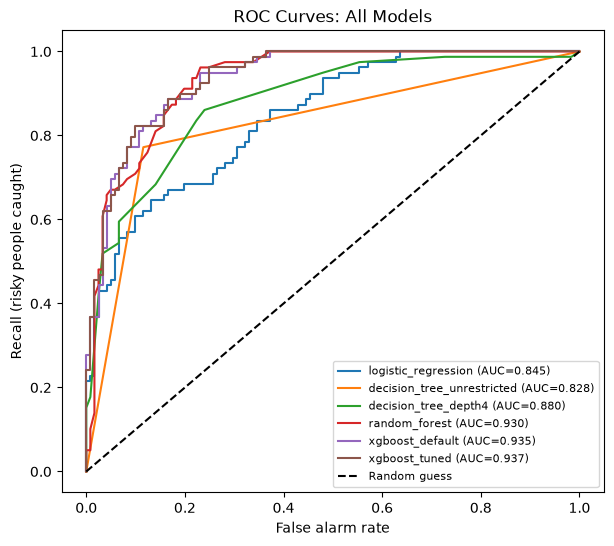

In [48]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

plt.figure(figsize=(7, 6))
for name, m in models.items():
    proba = m.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False alarm rate")
plt.ylabel("Recall (risky people caught)")
plt.title("ROC Curves: All Models")
plt.legend(loc="lower right", fontsize=8)
plt.savefig("Visualizations/roc_curves.png", dpi=150, bbox_inches="tight")
plt.show()

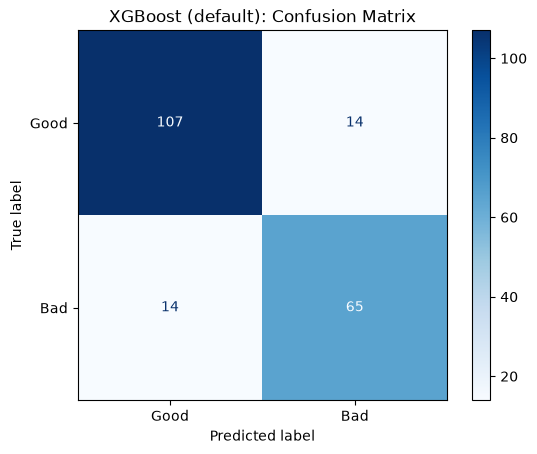

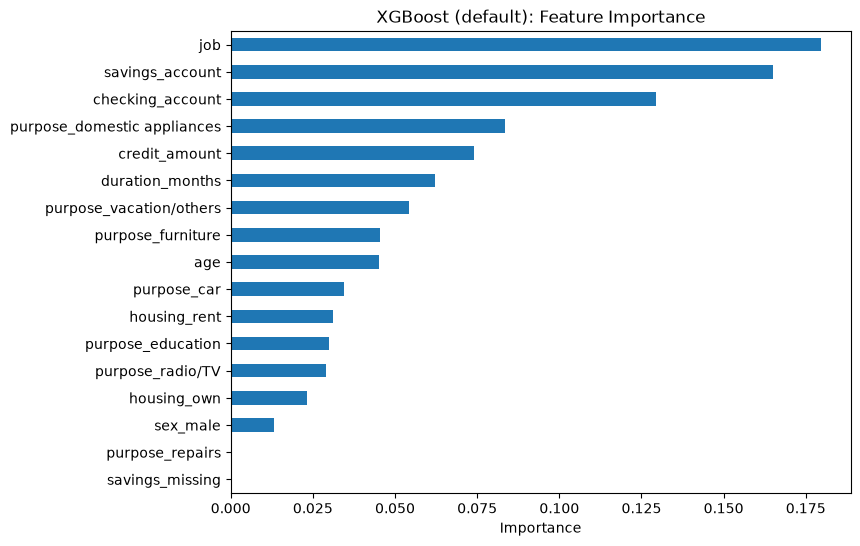

In [49]:
from sklearn.metrics import ConfusionMatrixDisplay

# Confusion matrix chart
ConfusionMatrixDisplay.from_estimator(
    xgb_model, X_test, y_test,
    display_labels=["Good", "Bad"], cmap="Blues"
)
plt.title("XGBoost (default): Confusion Matrix")
plt.savefig("Visualizations/confusion_matrix_xgb.png", dpi=150, bbox_inches="tight")
plt.show()

# Feature importance chart
importances = pd.Series(xgb_model.feature_importances_, index=X_train.columns).sort_values()
plt.figure(figsize=(8, 6))
importances.plot(kind="barh")
plt.title("XGBoost (default): Feature Importance")
plt.xlabel("Importance")
plt.savefig("Visualizations/feature_importance_xgb.png", dpi=150, bbox_inches="tight")
plt.show()

In [50]:
import joblib
joblib.dump(xgb_model, "Models/xgboost_final.pkl")

['Models/xgboost_final.pkl']